# Model 16: Morphological Substitution Cipher (Zohar / Aramaic)

## Hypothesis

Same morphological substitution cipher as Model 15, but targeting **Zohar (Aramaic)** instead of Torah (Hebrew).
If the Voynich author was a 15th-century Jewish kabbalist, Aramaic (the language of the Zohar) is a natural candidate.

| Table | Role | Aramaic chars | Estimated glyphs |
|-------|------|-------------|------------------|
| **P** (prefix) | Grammatical prefixes | ד,ב,כ,ל,מ,ו (6) | ~30-40 |
| **R** (root) | Root consonants | All 22 consonants | ~80-100 |
| **S** (suffix) | Grammatical suffixes | א,ה,ת,ן,ך,י (6) | ~20-30 |

Key difference from Hebrew: the definite article is a **suffix** (א-) not a prefix (ה-), and the relative particle is **ד** not **ש**.

Comparison with Model 15 (Torah/Hebrew) will determine if the morphological signal is language-specific.


In [1]:
# ── Cell 1: Imports ───────────────────────────────────────────────────
import re, math, time, copy, json, warnings, os
from collections import Counter, defaultdict
from itertools import combinations
from concurrent.futures import ProcessPoolExecutor
import multiprocessing as mp

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.spatial.distance import jensenshannon
from tqdm.auto import tqdm
import requests

# IMPORTANT: disable CUDA before importing torch to allow fork-based multiprocessing
os.environ['CUDA_VISIBLE_DEVICES'] = ''

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader

warnings.filterwarnings('ignore')
DEVICE = torch.device('cpu')  # force CPU — enables fork parallelism

# ── Parallelism config ──
N_CPUS = os.cpu_count() or 1
N_WORKERS = min(N_CPUS - 1, 10)
torch.set_num_threads(1)
torch.set_num_interop_threads(1)

print(f'Device: {DEVICE}')
print(f'CPUs: {N_CPUS}, Workers: {N_WORKERS}')

N_VOYNICH = 37_087

Device: cpu
CPUs: 16, Workers: 10


In [2]:
# ── Cell 2: Load Voynich corpus ─────────────────────────────────────
STA_PATH = 'corpus/voynich_sta.txt'

def parsear_sta_completo(filepath):
    tokens = []
    with open(filepath, 'r', encoding='utf-8') as f:
        for linea in f:
            linea = linea.strip()
            if not linea or linea.startswith('#'):
                continue
            if re.match(r'^<[^>]+>\s*<!', linea):
                continue
            match = re.match(r'^<[^>]+>\s+(.*)', linea)
            if not match:
                continue
            texto = match.group(1).strip()
            texto = re.sub(r'\{[^}]*\}', '', texto)
            texto = re.sub(r'<[^>]*>',   '', texto)
            texto = re.sub(r'-',          '.', texto)
            texto = texto.strip()
            if not texto:
                continue
            for palabra_raw in texto.split('.'):
                palabra_raw = palabra_raw.strip()
                if not palabra_raw:
                    continue
                glifos = re.findall(r'[A-Z][0-9a-z]', palabra_raw)
                if glifos:
                    tokens.extend(glifos)
                    tokens.append('.')
    return tokens

def tokens_a_palabras(tokens):
    palabras, actual = [], []
    for t in tokens:
        if t == '.':
            if actual:
                palabras.append(actual)
                actual = []
        else:
            actual.append(t)
    if actual:
        palabras.append(actual)
    return palabras

# ── Segmentation and positional classification ──
def construir_matriz_transicion_intrapalabra(palabras):
    all_glyphs = sorted({g for p in palabras for g in p})
    index = {g: i for i, g in enumerate(all_glyphs)}
    n = len(all_glyphs)
    M_raw = np.zeros((n, n))
    for palabra in palabras:
        for i in range(len(palabra) - 1):
            r, c = index[palabra[i]], index[palabra[i + 1]]
            M_raw[r, c] += 1
    row_sums = M_raw.sum(axis=1, keepdims=True)
    row_sums[row_sums == 0] = 1
    M_prob = M_raw / row_sums
    return M_raw, M_prob, all_glyphs, index

def segmentar_silabas_tp(palabras, M_prob, tokens_tr, index_tr, threshold_percentile=20):
    all_trans_probs = []
    for palabra in palabras:
        for i in range(len(palabra) - 1):
            g1, g2 = palabra[i], palabra[i + 1]
            if g1 in index_tr and g2 in index_tr:
                all_trans_probs.append(M_prob[index_tr[g1], index_tr[g2]])
    threshold_val = np.percentile(all_trans_probs, threshold_percentile)
    silabas_por_palabra = []
    for palabra in palabras:
        if len(palabra) == 0:
            continue
        syl = [palabra[0]]
        for i in range(len(palabra) - 1):
            g1, g2 = palabra[i], palabra[i + 1]
            p = M_prob[index_tr[g1], index_tr[g2]] if (g1 in index_tr and g2 in index_tr) else 0.0
            if p < threshold_val:
                silabas_por_palabra.append(syl)
                syl = [g2]
            else:
                syl.append(g2)
        silabas_por_palabra.append(syl)
    return silabas_por_palabra

def catalogar_silabas(silabas_por_palabra, palabras):
    syl_freq = Counter()
    for pal in palabras:
        syls = []
        idx = 0
        for s in silabas_por_palabra:
            if idx >= len(pal):
                break
            if pal[idx:idx+len(s)] == s:
                syls.append(tuple(s))
                idx += len(s)
        for s in syls:
            syl_freq[s] += 1
    return syl_freq

def clasificar_silabas_posicionalmente(palabras, M_prob, tokens_tr, index_tr, tp=20):
    silabas = segmentar_silabas_tp(palabras, M_prob, tokens_tr, index_tr, tp)
    syl_pos_counts = defaultdict(lambda: np.zeros(3))
    word_syls = []
    syl_idx = 0
    for pal in palabras:
        n_glifos = len(pal)
        w_syls = []
        pos = 0
        while syl_idx < len(silabas) and pos < n_glifos:
            s = silabas[syl_idx]
            if pal[pos:pos+len(s)] == list(s):
                w_syls.append(tuple(s))
                pos += len(s)
                syl_idx += 1
            else:
                break
        word_syls.append(w_syls)
    for w_syls in word_syls:
        n_s = len(w_syls)
        for i, s in enumerate(w_syls):
            if n_s == 1:
                syl_pos_counts[s] += [0.5, 0, 0.5]
            elif i == 0:
                syl_pos_counts[s][0] += 1
            elif i == n_s - 1:
                syl_pos_counts[s][2] += 1
            else:
                syl_pos_counts[s][1] += 1
    clase_silaba = {}
    for s, counts in syl_pos_counts.items():
        total = counts.sum()
        if total == 0:
            clase_silaba[s] = 'free'
            continue
        pcts = counts / total
        if pcts[0] >= 0.6:
            clase_silaba[s] = 'onset'
        elif pcts[2] >= 0.6:
            clase_silaba[s] = 'coda'
        elif pcts[1] >= 0.5:
            clase_silaba[s] = 'nuclear'
        else:
            clase_silaba[s] = 'free'
    return clase_silaba, syl_pos_counts

def syls_to_words(silabas, palabras):
    WORDS_SYL = []
    idx = 0
    for pal in palabras:
        w_syls = []
        pos = 0
        while idx < len(silabas) and pos < len(pal):
            s = silabas[idx]
            if pal[pos:pos+len(s)] == list(s):
                w_syls.append(tuple(s))
                pos += len(s)
                idx += 1
            else:
                break
        WORDS_SYL.append(w_syls)
    return WORDS_SYL

def clasificar_glifos(palabras, clase_silaba_v, WORDS_SYL_V):
    glyph_pos_counts = defaultdict(lambda: np.zeros(3))
    for w_syls in WORDS_SYL_V:
        for syl in w_syls:
            cls = clase_silaba_v.get(syl, 'free')
            for g in syl:
                if cls == 'onset':
                    glyph_pos_counts[g][0] += 1
                elif cls == 'nuclear':
                    glyph_pos_counts[g][1] += 1
                elif cls == 'coda':
                    glyph_pos_counts[g][2] += 1
                else:
                    glyph_pos_counts[g] += [0.33, 0.34, 0.33]
    glyph_stats = {}
    for g, counts in glyph_pos_counts.items():
        total = counts.sum()
        pcts = counts / total if total > 0 else np.array([1/3, 1/3, 1/3])
        glyph_stats[g] = {
            'pct_onset': pcts[0], 'pct_nuclear': pcts[1], 'pct_coda': pcts[2],
            'total': total
        }
    glyph_role = {}
    VOWEL_THRESHOLD = 0.55
    for g, st in glyph_stats.items():
        if st['pct_nuclear'] >= VOWEL_THRESHOLD:
            glyph_role[g] = 'V'
        elif st['pct_onset'] >= 0.6 or st['pct_coda'] >= 0.6:
            glyph_role[g] = 'C'
        else:
            glyph_role[g] = '?'
    return glyph_role, glyph_stats

# ── Parse ──
tokens = parsear_sta_completo(STA_PATH)
palabras = tokens_a_palabras(tokens)
VOCAB = sorted(set(g for p in palabras for g in p))
print(f'Voynich: {len(palabras):,} words, {len(VOCAB)} glyph types')

M_raw, M_prob, all_glyphs_tr, index_tr = construir_matriz_transicion_intrapalabra(palabras)
silabas_flat = segmentar_silabas_tp(palabras, M_prob, all_glyphs_tr, index_tr, 20)
clase_silaba_v, syl_pos_counts = clasificar_silabas_posicionalmente(
    palabras, M_prob, all_glyphs_tr, index_tr, 20)
WORDS_SYL_V = syls_to_words(silabas_flat, palabras)
glyph_role, glyph_stats = clasificar_glifos(palabras, clase_silaba_v, WORDS_SYL_V)

n_c = sum(1 for g in VOCAB if glyph_role.get(g) == 'C')
n_v = sum(1 for g in VOCAB if glyph_role.get(g) == 'V')
n_q = sum(1 for g in VOCAB if glyph_role.get(g) == '?')
print(f'Glyph roles: C={n_c}, V={n_v}, ?={n_q}')

# Glyph frequency
glyph_freq = Counter(g for p in palabras for g in p)
print(f'Total glyphs: {sum(glyph_freq.values()):,}')

Voynich: 37,087 words, 166 glyph types
Glyph roles: C=96, V=6, ?=64
Total glyphs: 157,254


In [3]:
# ── Cell 3: Corpus Zohar (Aramaic) + Morphological setup ──────────────

def descargar_zohar():
    url = ('https://raw.githubusercontent.com/Sefaria/Sefaria-Export/'
           'master/json/Kabbalah/Zohar/Zohar/Hebrew/'
           'Sulam%20Edition%2C%20Jerusalem%201945.json')
    print(f'  Downloading Zohar (this may take a while, ~8MB)...')
    resp = requests.get(url, timeout=120)
    resp.raise_for_status()
    data = resp.json()
    todas_palabras = []
    text_data = data['text']
    def process_text(texto):
        texto = re.sub(r'<[^>]*>', '', texto)
        texto = re.sub(r'\([^)]*\)', '', texto)
        texto = re.sub(r'[\u0591-\u05C7]', '', texto)
        pals = re.findall(r'[\u05D0-\u05EA]+', texto)
        for p in pals:
            chars = list(p)
            if 2 <= len(chars) <= 15:
                todas_palabras.append(chars)
    def walk(obj):
        if isinstance(obj, str):
            process_text(obj)
        elif isinstance(obj, list):
            for item in obj:
                walk(item)
        elif isinstance(obj, dict):
            for v in obj.values():
                walk(v)
    walk(text_data)
    print(f'  Zohar total: {len(todas_palabras):,} words')
    return todas_palabras

print('Downloading Zohar corpus (Aramaic)...')
zohar_words_full = descargar_zohar()

rng_sub = np.random.default_rng(42)
if len(zohar_words_full) > N_VOYNICH:
    idx = rng_sub.choice(len(zohar_words_full), size=N_VOYNICH, replace=False)
    target_words = [zohar_words_full[i] for i in sorted(idx)]
else:
    target_words = zohar_words_full
print(f'Zohar subsampled: {len(target_words):,} words')

# C/V classification — same matres lectionis in Aramaic
ARAMAIC_VOWELS = set('אהוי')
target_chars_heb = sorted(set(c for w in target_words for c in w))
char_role_heb = {c: 'V' if c in ARAMAIC_VOWELS else 'C' for c in target_chars_heb}
n_c_h = sum(1 for c in target_chars_heb if char_role_heb[c] == 'C')
n_v_h = sum(1 for c in target_chars_heb if char_role_heb[c] == 'V')
print(f'Aramaic chars: {len(target_chars_heb)} (C={n_c_h}, V={n_v_h})')

# ── Aramaic morphological sets ──
# Zoharic Aramaic prefixes: ד (di-/de- relative), ב, כ, ל, מ (min), ו (conjunction)
HEBREW_PREFIX_CHARS = set('דבכלמו')  # 6 chars (no ה/ש unlike Hebrew)
# Aramaic suffixes: א (definite/emphatic), ה, ת, ן, ך, י (pronominal)
HEBREW_SUFFIX_CHARS = set('אהתןךי')  # 6 chars (א is the big difference)
# Final-form equivalents
FINAL_TO_NORMAL = {'ך': 'כ', 'ם': 'מ', 'ן': 'נ', 'ף': 'פ', 'ץ': 'צ'}
# All 22 consonants (root candidates)
HEBREW_ROOT_CHARS = set('אבגדהוזחטיכלמנסעפצקרשת')

print(f'\nMorphological sets (Aramaic):')
print(f'  Prefix chars (P): {len(HEBREW_PREFIX_CHARS)} — {"".join(sorted(HEBREW_PREFIX_CHARS))}')
print(f'  Suffix chars (S): {len(HEBREW_SUFFIX_CHARS)} — {"".join(sorted(HEBREW_SUFFIX_CHARS))}')
print(f'  Root chars (R):   {len(HEBREW_ROOT_CHARS)} — all 22 consonants')

# ── Grammar anchors ──
def build_glyph_grammar_roles(palabras, glyph_stats, target_words):
    anchors = {}
    for g in glyph_stats:
        st = glyph_stats[g]
        if st['pct_onset'] >= 0.7:
            anchors[g] = HEBREW_PREFIX_CHARS
        elif st['pct_coda'] >= 0.7:
            anchors[g] = HEBREW_SUFFIX_CHARS
    return anchors

glyph_anchor_sets = build_glyph_grammar_roles(palabras, glyph_stats, target_words)
print(f'Grammar anchors: {len(glyph_anchor_sets)} glyphs anchored')

# ── Aramaic morphological segmentation (rule-based) ──
# Aramaic prefixes: ד (relative), ב, כ, ל, מ, ו + combinations
KNOWN_PREFIXES = ['וד', 'ובד', 'וב', 'וכ', 'ול', 'ומ',
                  'דב', 'דכ', 'דל', 'דמ',
                  'מד', 'מב', 'מכ', 'מל',
                  'כד', 'כב', 'כל',
                  'לד', 'לב', 'לכ', 'למ',
                  'ב', 'כ', 'ל', 'מ', 'ד', 'ו']

# Aramaic suffixes: א (definite/emphatic), pronominal suffixes
KNOWN_SUFFIXES = ['תהון', 'הון', 'כון',
                  'תא', 'ין', 'ון',
                  'ן', 'ך', 'ת', 'ה', 'א', 'י']

def segment_hebrew_word(chars):
    """Segment an Aramaic word into (prefix_chars, root_chars, suffix_chars).
    Rule-based: greedy prefix stripping, then greedy suffix stripping,
    with min 2-char root constraint."""
    word = ''.join(chars)
    prefix = ''
    root_start = 0
    for pfx in KNOWN_PREFIXES:
        if word.startswith(pfx) and len(word) - len(pfx) >= 2:
            prefix = pfx
            root_start = len(pfx)
            break
    suffix = ''
    root_end = len(word)
    remaining = word[root_start:]
    for sfx in KNOWN_SUFFIXES:
        if remaining.endswith(sfx) and len(remaining) - len(sfx) >= 2:
            suffix = sfx
            root_end = len(word) - len(sfx)
            break
    root = word[root_start:root_end]
    roles = []
    for i, c in enumerate(word):
        if i < root_start:
            roles.append('P')
        elif i >= root_end:
            roles.append('S')
        else:
            roles.append('R')
    return roles, prefix, root, suffix

# Test morphological segmentation on Aramaic words
test_words = [list('דאיהו'), list('בגין'), list('קדישא'), list('למלכא'), list('ואתמר')]
print('\nAramaic morphological segmentation examples:')
for tw in test_words:
    roles, pfx, root, sfx = segment_hebrew_word(tw)
    print(f'  {"".join(tw):>8s} → P=[{pfx}] R=[{root}] S=[{sfx}]  roles={roles}')

# Compute morphological role distribution
role_dist = Counter()
for w in target_words:
    roles, _, _, _ = segment_hebrew_word(w)
    role_dist.update(roles)
total_roles = sum(role_dist.values())
print(f'\nAramaic morphological role distribution:')
for r in ['P', 'R', 'S']:
    print(f'  {r}: {role_dist[r]:,} ({100*role_dist[r]/total_roles:.1f}%)')

# Alias for compatibility with rest of notebook
hebrew_words = target_words


Descargando corpus Zohar (Aramaic)...
  Descargando Zohar (puede tardar, ~8MB)...
  Zohar total: 807,843 palabras
Zohar subsampleado: 37,087 palabras
Aramaic chars: 27 (C=23, V=4)

Morphological sets (Aramaic):
  Prefix chars (P): 6 — בדוכלמ
  Suffix chars (S): 6 — אהיךןת
  Root chars (R):   22 — all 22 consonants
Grammar anchors: 80 glyphs anchored

Aramaic morphological segmentation examples:
     דאיהו → P=[ד] R=[איהו] S=[]  roles=['P', 'R', 'R', 'R', 'R']
      בגין → P=[ב] R=[גי] S=[ן]  roles=['P', 'R', 'R', 'S']
     קדישא → P=[] R=[קדיש] S=[א]  roles=['R', 'R', 'R', 'R', 'S']
     למלכא → P=[למ] R=[לכ] S=[א]  roles=['P', 'P', 'R', 'R', 'S']
     ואתמר → P=[ו] R=[אתמר] S=[]  roles=['P', 'R', 'R', 'R', 'R']

Aramaic morphological role distribution:
  P: 21,412 (13.8%)
  R: 111,497 (71.7%)
  S: 22,514 (14.5%)


Char vocab: 31 tokens
Train: 29,670, Val: 7,417

Entrenando Neural LM (30 epochs, patience=5)...
  Epoch  1: train=2.4169, val=2.2444
  Epoch  5: train=2.1624, val=2.1341
  Epoch 10: train=2.1373, val=2.1217
  Epoch 15: train=2.1235, val=2.1159
  Epoch 20: train=2.1145, val=2.1121
  Epoch 25: train=2.1075, val=2.1108
  Epoch 30: train=2.1053, val=2.1105

Best val_loss: 2.1105 (191.5s)


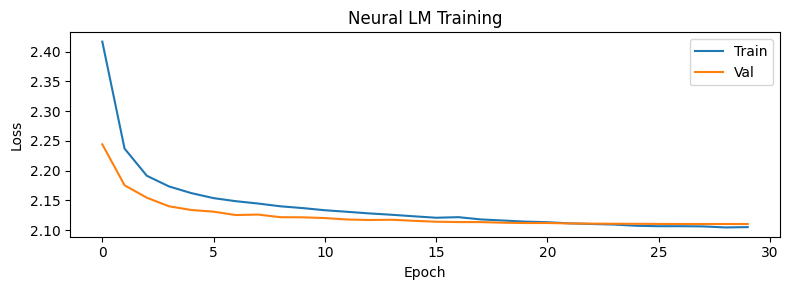

In [4]:
# ── Cell 4: NeuralCharLM — Architecture + Training ───────────────

class CharDataset(Dataset):
    def __init__(self, words, char2idx):
        self.samples = []
        bos = char2idx['<w>']
        eos = char2idx['</w>']
        for word in words:
            indices = [bos, bos] + [char2idx.get(c, char2idx.get('<unk>', 0)) for c in word] + [eos]
            for i in range(2, len(indices)):
                ctx = indices[i-2:i]
                target = indices[i]
                self.samples.append((ctx, target))
    def __len__(self):
        return len(self.samples)
    def __getitem__(self, idx):
        ctx, target = self.samples[idx]
        return torch.tensor(ctx, dtype=torch.long), torch.tensor(target, dtype=torch.long)

class NeuralCharLM(nn.Module):
    def __init__(self, vocab_size, embed_dim=32, hidden_dim=192, n_layers=2, dropout=0.2):
        super().__init__()
        self.vocab_size = vocab_size
        self.embed_dim = embed_dim
        self.hidden_dim = hidden_dim
        self.n_layers = n_layers
        self.embedding = nn.Embedding(vocab_size, embed_dim)
        self.lstm = nn.LSTM(embed_dim, hidden_dim, num_layers=n_layers,
                           dropout=dropout if n_layers > 1 else 0.0, batch_first=True)
        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(hidden_dim, vocab_size)
        self.char2idx = None
        self.idx2char = None

    def forward(self, x, hidden=None):
        emb = self.dropout(self.embedding(x))
        out, hidden = self.lstm(emb, hidden)
        out = self.dropout(out)
        logits = self.fc(out)
        return logits, hidden

    def log_prob(self, word, temperature=1.0):
        self.eval()
        with torch.no_grad():
            bos = self.char2idx['<w>']
            eos = self.char2idx['</w>']
            unk = self.char2idx.get('<unk>', 0)
            indices = [bos, bos] + [self.char2idx.get(c, unk) for c in word] + [eos]
            total_lp = 0.0
            for i in range(2, len(indices)):
                ctx = torch.tensor([[indices[i-2], indices[i-1]]], device=DEVICE)
                logits, _ = self.forward(ctx)
                logits_t = logits[0, -1, :] / temperature
                log_probs = torch.log_softmax(logits_t, dim=0)
                total_lp += log_probs[indices[i]].item() / math.log(2)
            return total_lp

    def batch_log_prob(self, words, temperature=1.0):
        self.eval()
        bos = self.char2idx['<w>']
        eos = self.char2idx['</w>']
        unk = self.char2idx.get('<unk>', 0)
        with torch.no_grad():
            all_ctx, all_tgt = [], []
            word_boundaries = [0]
            for word in words:
                seq = [bos, bos] + [self.char2idx.get(c, unk) for c in word] + [eos]
                for i in range(2, len(seq)):
                    all_ctx.append([seq[i-2], seq[i-1]])
                    all_tgt.append(seq[i])
                word_boundaries.append(len(all_ctx))
            n_total = len(all_ctx)
            if n_total == 0:
                return np.zeros(len(palabras))
            ctx_t = torch.tensor(all_ctx, device=DEVICE)
            tgt_t = torch.tensor(all_tgt, device=DEVICE)
            BATCH = 4096
            all_lps = np.zeros(n_total)
            for start in range(0, n_total, BATCH):
                end = min(start + BATCH, n_total)
                logits, _ = self.forward(ctx_t[start:end])
                logits_t = logits[:, -1, :] / temperature
                log_probs = torch.log_softmax(logits_t, dim=0)
                for j in range(end - start):
                    all_lps[start + j] = log_probs[j, tgt_t[start + j]].item() / math.log(2)
            word_lps = np.zeros(len(palabras))
            for wi in range(len(palabras)):
                s, e = word_boundaries[wi], word_boundaries[wi + 1]
                if s < e:
                    word_lps[wi] = all_lps[s:e].sum()
            return word_lps

# ── Build vocab and train ──
char_vocab = ['<pad>', '<w>', '</w>', '<unk>'] + target_chars_heb
char2idx = {c: i for i, c in enumerate(char_vocab)}
idx2char = {i: c for c, i in char2idx.items()}
print(f'Char vocab: {len(char_vocab)} tokens')

rng_split = np.random.default_rng(42)
n_val = int(0.2 * len(hebrew_words))
perm = rng_split.permutation(len(hebrew_words))
val_idx = set(perm[:n_val])
train_words = [hebrew_words[i] for i in range(len(hebrew_words)) if i not in val_idx]
val_words = [hebrew_words[i] for i in range(len(hebrew_words)) if i in val_idx]
print(f'Train: {len(train_words):,}, Val: {len(val_words):,}')

train_dataset = CharDataset(train_words, char2idx)
val_dataset = CharDataset(val_words, char2idx)
train_loader = DataLoader(train_dataset, batch_size=256, shuffle=True, num_workers=0)
val_loader = DataLoader(val_dataset, batch_size=256, shuffle=False, num_workers=0)

neural_lm = NeuralCharLM(len(char_vocab), embed_dim=32, hidden_dim=192,
                          n_layers=2, dropout=0.2).to(DEVICE)
neural_lm.char2idx = char2idx
neural_lm.idx2char = idx2char

optimizer = optim.AdamW(neural_lm.parameters(), lr=2e-3, weight_decay=1e-4)
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=30)
criterion = nn.CrossEntropyLoss(ignore_index=char2idx['<pad>'])

N_EPOCHS, PATIENCE = 30, 5
best_val_loss = float('inf')
patience_counter = 0
train_losses, val_losses = [], []

print(f'\nEntrenando Neural LM ({N_EPOCHS} epochs, patience={PATIENCE})...')
t0 = time.time()
for epoch in range(N_EPOCHS):
    neural_lm.train()
    epoch_loss, n_batches = 0.0, 0
    for ctx_batch, target_batch in train_loader:
        ctx_batch, target_batch = ctx_batch.to(DEVICE), target_batch.to(DEVICE)
        optimizer.zero_grad()
        logits, _ = neural_lm(ctx_batch)
        loss = criterion(logits[:, -1, :], target_batch)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(neural_lm.parameters(), 1.0)
        optimizer.step()
        epoch_loss += loss.item()
        n_batches += 1
    train_loss = epoch_loss / max(n_batches, 1)
    train_losses.append(train_loss)

    neural_lm.eval()
    vl, n_vb = 0.0, 0
    with torch.no_grad():
        for ctx_batch, target_batch in val_loader:
            ctx_batch, target_batch = ctx_batch.to(DEVICE), target_batch.to(DEVICE)
            logits, _ = neural_lm(ctx_batch)
            loss = criterion(logits[:, -1, :], target_batch)
            vl += loss.item()
            n_vb += 1
    val_loss = vl / max(n_vb, 1)
    val_losses.append(val_loss)
    scheduler.step()

    if (epoch + 1) % 5 == 0 or epoch == 0:
        print(f'  Epoch {epoch+1:2d}: train={train_loss:.4f}, val={val_loss:.4f}')

    if val_loss < best_val_loss - 1e-4:
        best_val_loss = val_loss
        patience_counter = 0
        best_state_dict = copy.deepcopy(neural_lm.state_dict())
    else:
        patience_counter += 1
        if patience_counter >= PATIENCE:
            print(f'  Early stopping at epoch {epoch+1}')
            break

neural_lm.load_state_dict(best_state_dict)
neural_lm.eval()
elapsed = time.time() - t0
print(f'\nBest val_loss: {best_val_loss:.4f} ({elapsed:.1f}s)')

fig, ax = plt.subplots(1, 1, figsize=(8, 3))
ax.plot(train_losses, label='Train')
ax.plot(val_losses, label='Val')
ax.set_xlabel('Epoch'); ax.set_ylabel('Loss'); ax.legend()
ax.set_title('Neural LM Training')
plt.tight_layout(); plt.show()

In [5]:
# ── Cell 5: MorphMappingState + Morphological Scoring ─────────────────
# THE KEY INNOVATION: each glyph maps to (Hebrew char, morphological role)

MORPH_ROLES = ('P', 'R', 'S')  # Prefix, Root, Suffix

# Valid chars per morphological role
ROLE_CHARS = {
    'P': sorted(HEBREW_PREFIX_CHARS & set(target_chars_heb)),  # ב,ה,ו,כ,ל,מ,ש
    'R': sorted(set(target_chars_heb)),                        # all 22 consonants
    'S': sorted(HEBREW_SUFFIX_CHARS & set(target_chars_heb)),  # ה,ך,ם,ן,ת
}
for r in MORPH_ROLES:
    print(f'Role {r}: {len(ROLE_CHARS[r])} chars — {"".join(ROLE_CHARS[r])}')


class MorphMappingState:
    """Each glyph maps to (Hebrew char, morphological role).
    The role determines WHICH substitution table the glyph belongs to."""

    def __init__(self, voynich_glyphs, target_chars):
        self.voynich_glyphs = list(voynich_glyphs)
        self.target_chars = list(target_chars)
        self.mapping = {}       # glyph → Hebrew char
        self.glyph_role = {}    # glyph → morphological role ('P', 'R', 'S')

    def set_mapping(self, mapping_dict, role_dict):
        self.mapping = dict(mapping_dict)
        self.glyph_role = dict(role_dict)

    def propose_char_change(self, rng):
        """70% of proposals: change char within current role's valid set."""
        new = MorphMappingState(self.voynich_glyphs, self.target_chars)
        new.mapping = dict(self.mapping)
        new.glyph_role = dict(self.glyph_role)
        glyph = rng.choice(self.voynich_glyphs)
        role = new.glyph_role.get(glyph, 'R')
        candidates = ROLE_CHARS[role]
        new.mapping[glyph] = rng.choice(candidates)
        return new, glyph

    def propose_role_change(self, rng):
        """30% of proposals: reassign glyph to a different morphological role,
        and pick a valid char for the new role."""
        new = MorphMappingState(self.voynich_glyphs, self.target_chars)
        new.mapping = dict(self.mapping)
        new.glyph_role = dict(self.glyph_role)
        glyph = rng.choice(self.voynich_glyphs)
        current_role = new.glyph_role.get(glyph, 'R')
        other_roles = [r for r in MORPH_ROLES if r != current_role]
        new_role = rng.choice(other_roles)
        new.glyph_role[glyph] = new_role
        candidates = ROLE_CHARS[new_role]
        new.mapping[glyph] = rng.choice(candidates)
        return new, glyph

    def propose_change_tracked(self, rng):
        """Mixed proposal: 70% char change, 30% role change."""
        if rng.random() < 0.7:
            return self.propose_char_change(rng)
        else:
            return self.propose_role_change(rng)

    def apply_word(self, word_glyphs):
        return [self.mapping.get(g, '?') for g in word_glyphs]

    def apply_word_with_roles(self, word_glyphs):
        """Returns [(char, role), ...] for each glyph in the word."""
        return [(self.mapping.get(g, '?'), self.glyph_role.get(g, 'R'))
                for g, in zip(word_glyphs)]

    def apply_corpus(self, words):
        return [self.apply_word(w) for w in words]

    def get_role_tables(self):
        """Return the 3 substitution tables."""
        tables = {'P': {}, 'R': {}, 'S': {}}
        for g in self.voynich_glyphs:
            role = self.glyph_role.get(g, 'R')
            tables[role][g] = self.mapping.get(g, '?')
        return tables


def init_morph_mapping(palabras, vocab_glyphs, glyph_stats_dict):
    """Initialize morphological mapping using positional statistics as proxy.
    onset-dominant → P (prefix), nuclear-dominant → R (root), coda-dominant → S (suffix)."""
    rng_init = np.random.default_rng(42)
    mapping = {}
    roles = {}

    gf = Counter(g for p in palabras for g in p)

    for g in vocab_glyphs:
        st = glyph_stats_dict.get(g, {'pct_onset': 0.33, 'pct_nuclear': 0.34, 'pct_coda': 0.33})
        # Assign morphological role based on positional distribution
        if st['pct_onset'] >= 0.5:
            role = 'P'
        elif st['pct_coda'] >= 0.5:
            role = 'S'
        else:
            role = 'R'
        roles[g] = role
        # Initial char: random from role's valid set
        mapping[g] = rng_init.choice(ROLE_CHARS[role])

    return mapping, roles


def build_glyph_word_index(words):
    idx = defaultdict(list)
    for wi, word in enumerate(words):
        for g in set(word):
            idx[g].append(wi)
    return idx


# ── Scoring functions ──

def score_neural_lm_batch(mapping_state, words_sample, neural_lm, temperature=1.0):
    mapped = [mapping_state.apply_word(w) for w in words_sample]
    word_lps = neural_lm.batch_log_prob(mapped, temperature)
    return float(np.mean(word_lps)), word_lps


def score_cardinality(mapping_state, K_max=23):
    K = len(set(mapping_state.mapping.values()))
    if K >= K_max:
        return 0.0
    return -((K_max - K) ** 2)


def score_entropy(mapping_state):
    char_counts = Counter(mapping_state.mapping.values())
    if len(char_counts) <= 1:
        return 0.0
    total = sum(char_counts.values())
    probs = np.array([c / total for c in char_counts.values()])
    probs = probs[probs > 0]
    H = -np.sum(probs * np.log2(probs))
    H_max = np.log2(len(char_counts))
    return H / H_max if H_max > 1e-10 else 0.0


def score_morph_consistency(mapping_state, words_sample, decoded_cache=None):
    """THE KEY SCORE: for each decoded word, segment into prefix/root/suffix,
    then check if each glyph's assigned role matches the morphological segment
    it falls in. Returns fraction of consistent assignments.

    This is the morphological signal that no other model captures."""
    n_consistent = 0
    n_total = 0

    for wi, word_glyphs in enumerate(words_sample):
        mapped_chars = mapping_state.apply_word(word_glyphs)
        roles_assigned = [mapping_state.glyph_role.get(g, 'R') for g in word_glyphs]

        # Segment the decoded Hebrew word
        morph_roles, _, _, _ = segment_hebrew_word(mapped_chars)

        # Compare assigned roles vs morphological segmentation
        min_len = min(len(roles_assigned), len(morph_roles))
        for i in range(min_len):
            n_total += 1
            if roles_assigned[i] == morph_roles[i]:
                n_consistent += 1

    return n_consistent / max(n_total, 1)


def score_role_distribution(mapping_state):
    """Penalize if role distribution is very imbalanced.
    Expected: P ~20%, R ~60%, S ~20% (from Hebrew morphology)."""
    role_counts = Counter(mapping_state.glyph_role.values())
    total = sum(role_counts.values())
    if total == 0:
        return 0.0
    pcts = {r: role_counts.get(r, 0) / total for r in MORPH_ROLES}
    # Penalize if any role has 0 glyphs or >80%
    penalty = 0.0
    for r in MORPH_ROLES:
        if pcts[r] < 0.05:
            penalty -= 2.0
        if pcts[r] > 0.80:
            penalty -= 1.0
    return penalty


def score_total_morph(mapping_state, words_sample, neural_lm, temperature,
                      w_lm=2.0, w_morph=3.0, w_card=0.5, w_ent=0.3, w_role=0.5,
                      K_max=23):
    """Combined score with morphological consistency as key component."""
    s_lm, word_lps = score_neural_lm_batch(mapping_state, words_sample, neural_lm, temperature)
    s_morph = score_morph_consistency(mapping_state, words_sample)
    s_card = score_cardinality(mapping_state, K_max)
    s_ent = score_entropy(mapping_state)
    s_role = score_role_distribution(mapping_state)
    total = (w_lm * s_lm + w_morph * s_morph + w_card * s_card
             + w_ent * s_ent + w_role * s_role)
    return total, word_lps


def score_total_morph_incremental(proposal, changed_glyph, words_sample, neural_lm,
                                  temperature, glyph_word_idx, prev_word_lps,
                                  w_lm=2.0, w_morph=3.0, w_card=0.5, w_ent=0.3,
                                  w_role=0.5, K_max=23):
    """Incremental scoring: only re-score words affected by the changed glyph."""
    new_word_lps = prev_word_lps.copy()
    affected = glyph_word_idx.get(changed_glyph, [])
    if affected:
        affected_mapped = [proposal.apply_word(words_sample[wi]) for wi in affected]
        new_lps = neural_lm.batch_log_prob(affected_mapped, temperature)
        for j, wi in enumerate(affected):
            new_word_lps[wi] = new_lps[j]
    s_lm = float(np.mean(new_word_lps))
    # Morphological consistency on affected words only would be imprecise;
    # compute on a subsample for speed
    subsample_idx = affected[:200] if len(affected) > 200 else affected
    if subsample_idx:
        n_con, n_tot = 0, 0
        for wi in subsample_idx:
            word_glyphs = words_sample[wi]
            mapped_chars = proposal.apply_word(word_glyphs)
            roles_assigned = [proposal.glyph_role.get(g, 'R') for g in word_glyphs]
            morph_roles, _, _, _ = segment_hebrew_word(mapped_chars)
            min_len = min(len(roles_assigned), len(morph_roles))
            for i in range(min_len):
                n_tot += 1
                if roles_assigned[i] == morph_roles[i]:
                    n_con += 1
        s_morph = n_con / max(n_tot, 1)
    else:
        s_morph = score_morph_consistency(proposal, words_sample)

    s_card = score_cardinality(proposal, K_max)
    s_ent = score_entropy(proposal)
    s_role = score_role_distribution(proposal)
    total = (w_lm * s_lm + w_morph * s_morph + w_card * s_card
             + w_ent * s_ent + w_role * s_role)
    return total, new_word_lps


# ── Root helpers (from neural v2) ──
HEBREW_CONSONANTS_SET = set('בגדהוזחטיכלמנסעפצקרשת') | set('ךםןףץ')
HEBREW_MATRES = set('אוי')
HEBREW_ROOTS = {
    'אמר', 'דבר', 'היה', 'בוא', 'עשה', 'נתן', 'ידע', 'הלך', 'ראה', 'שמע',
    'אכל', 'לקח', 'ישב', 'קרא', 'שלח', 'עלה', 'מות', 'שוב', 'ברך', 'יצא',
    'עבר', 'שמר', 'כתב', 'נשא', 'זכר', 'ילד', 'עמד', 'פנה', 'בנה', 'נפל',
    'שים', 'חיה', 'גדל', 'קום', 'מלא', 'מצא', 'שפט', 'אהב', 'ירד', 'נגד',
    'יסף', 'חטא', 'קדש', 'כהן', 'צוה', 'ברא', 'גלה', 'זבח', 'טהר', 'טמא',
    'ארץ', 'בית', 'שנה', 'יום', 'מים', 'שמש', 'ליל', 'אבן', 'עיר', 'דרך',
    'מלך', 'כסף', 'זהב', 'דמם', 'רוח', 'נפש', 'לחם', 'עין', 'ידד', 'שדה',
    'עבד', 'כלי', 'פרי', 'חדש', 'ספר', 'עצם', 'בשר', 'אדם', 'נהר', 'גבר',
    'רגל', 'ראש', 'חזק', 'רבב', 'קטן', 'טוב', 'רעע', 'חכם', 'צדק', 'רחם',
    'כול', 'בקר', 'צאן', 'עוף', 'דגג', 'שמן', 'יין', 'סוס', 'גמל', 'חמר',
}

def extract_skeleton_deterministic(mapped_word):
    skeleton = []
    for char in mapped_word:
        if char in HEBREW_MATRES:
            continue
        if char in HEBREW_CONSONANTS_SET:
            skeleton.append(char)
    return ''.join(skeleton)

def count_roots_quick(mapping, palabras_sample, top_n=200):
    word_freq = Counter(tuple(w) for w in palabras_sample)
    top_words = word_freq.most_common(top_n)
    roots_matched = set()
    n_matches = 0
    for word_tuple, freq in top_words:
        mapped = [mapping.get(g, '?') for g in word_tuple]
        skel = extract_skeleton_deterministic(mapped)
        if len(skel) < 3:
            continue
        for i in range(len(skel) - 2):
            trigram = skel[i:i+3]
            if trigram in HEBREW_ROOTS:
                roots_matched.add(trigram)
                n_matches += 1
    return roots_matched, n_matches


# ── Initialize and test ──
base_mapping, base_roles = init_morph_mapping(palabras, VOCAB, glyph_stats)

role_counts = Counter(base_roles.values())
print(f'\nInitial role distribution:')
for r in MORPH_ROLES:
    print(f'  {r}: {role_counts.get(r, 0)} glyphs ({100*role_counts.get(r, 0)/len(VOCAB):.1f}%)')

# Quick test
test_state = MorphMappingState(VOCAB, target_chars_heb)
test_state.set_mapping(base_mapping, base_roles)
test_morph = score_morph_consistency(test_state, palabras[:100])
print(f'\nInitial morphological consistency (100 words): {test_morph:.3f}')

tables = test_state.get_role_tables()
for r in MORPH_ROLES:
    chars_used = set(tables[r].values())
    print(f'Table {r}: {len(tables[r])} glyphs → {len(chars_used)} unique chars')

print(f'\nScoring functions loaded. Hebrew roots: {len(HEBREW_ROOTS)}')

Role P: 6 chars — בדוכלמ
Role R: 27 chars — אבגדהוזחטיךכלםמןנסעףפץצקרשת
Role S: 6 chars — אהיךןת

Initial role distribution:
  P: 18 glyphs (10.8%)
  R: 53 glyphs (31.9%)
  S: 95 glyphs (57.2%)

Initial morphological consistency (100 words): 0.430
Table P: 18 glyphs → 5 unique chars
Table R: 53 glyphs → 23 unique chars
Table S: 95 glyphs → 6 unique chars

Scoring functions loaded. Hebrew roots: 100


In [6]:
# ── Cell 6: Multi-Seed EM (Parallel) ────────────────────────────────────

N_SEEDS = 20
T_FIXED = 3.0
SCORE_KW = dict(w_lm=2.0, w_morph=3.0, w_card=0.5, w_ent=0.3, w_role=0.5, K_max=20)
SAMPLE_EM = 1500
EM_ITERS = 2000
EM_PATIENCE = 100
PROPOSALS_PER_ITER = 200

# Prepare EM sample
rng_sample = np.random.default_rng(42)
if len(palabras) > SAMPLE_EM:
    idx_em = rng_sample.choice(len(palabras), size=SAMPLE_EM, replace=False)
    words_em = [palabras[i] for i in idx_em]
else:
    words_em = palabras

glyph_word_idx_em = build_glyph_word_index(words_em)
base_mapping, base_roles = init_morph_mapping(palabras, VOCAB, glyph_stats)


def run_one_seed(seed_idx):
    """Run a single EM seed — designed to be called in a subprocess."""
    # Each subprocess: 1 torch thread
    torch.set_num_threads(1)

    rng = np.random.default_rng(42 + seed_idx * 137)
    state = MorphMappingState(VOCAB, target_chars_heb)

    if seed_idx < 10:
        mapping_init = dict(base_mapping)
        roles_init = dict(base_roles)
        glyphs_to_scramble = rng.choice(VOCAB, size=max(1, len(VOCAB) // 3), replace=False)
        for g in glyphs_to_scramble:
            new_role = rng.choice(list(MORPH_ROLES))
            roles_init[g] = new_role
            mapping_init[g] = rng.choice(ROLE_CHARS[new_role])
        state.set_mapping(mapping_init, roles_init)
    else:
        mapping_init, roles_init = {}, {}
        for g in VOCAB:
            role = rng.choice(list(MORPH_ROLES))
            roles_init[g] = role
            mapping_init[g] = rng.choice(ROLE_CHARS[role])
        state.set_mapping(mapping_init, roles_init)

    best_score, best_word_lps = score_total_morph(
        state, words_em, neural_lm, T_FIXED, **SCORE_KW)
    best_state = state
    no_improve = 0

    t0 = time.time()
    for it in range(EM_ITERS):
        improved = False
        for _ in range(PROPOSALS_PER_ITER):
            proposal, changed_glyph = best_state.propose_change_tracked(rng)
            prop_score, prop_word_lps = score_total_morph_incremental(
                proposal, changed_glyph, words_em, neural_lm, T_FIXED,
                glyph_word_idx_em, best_word_lps, **SCORE_KW)
            if prop_score > best_score:
                best_state = proposal
                best_score = prop_score
                best_word_lps = prop_word_lps
                improved = True
        if not improved:
            no_improve += 1
            if no_improve >= EM_PATIENCE:
                break
        else:
            no_improve = 0

    elapsed = time.time() - t0
    roots, n_root_matches = count_roots_quick(best_state.mapping, palabras)
    K_eff = len(set(best_state.mapping.values()))
    morph_cons = score_morph_consistency(best_state, words_em)
    role_dist = Counter(best_state.glyph_role.values())

    return {
        'seed': seed_idx, 'score': best_score, 'K_eff': K_eff,
        'n_roots': len(roots), 'roots': roots,
        'morph_consistency': morph_cons,
        'role_P': role_dist.get('P', 0), 'role_R': role_dist.get('R', 0),
        'role_S': role_dist.get('S', 0),
        'iter_converged': it + 1, 'elapsed': elapsed,
        'mapping': dict(best_state.mapping),
        'glyph_role': dict(best_state.glyph_role),
    }


print(f'Multi-Seed EM: {N_SEEDS} seeds, T={T_FIXED}, {SAMPLE_EM} words, {EM_ITERS} iter')
print(f'Workers: {N_WORKERS} (parallel seeds)')
print(f'Score weights: {SCORE_KW}')
print()

t0_total = time.time()

# ── Fork-based parallelism (Linux default) ──
# All globals (neural_lm, words_em, VOCAB, etc.) are inherited via fork
with ProcessPoolExecutor(max_workers=N_WORKERS,
                         mp_context=mp.get_context('fork')) as executor:
    futures = {executor.submit(run_one_seed, s): s for s in range(N_SEEDS)}
    multi_seed_results = []
    for future in futures:
        result = future.result()
        # Reconstruct MorphMappingState for later use
        state = MorphMappingState(VOCAB, target_chars_heb)
        state.set_mapping(result['mapping'], result['glyph_role'])
        result['state'] = state
        multi_seed_results.append(result)
        s = result['seed']
        print(f'Seed {s:2d}: score={result["score"]:.2f}, K={result["K_eff"]}, '
              f'roots={result["n_roots"]}, morph={result["morph_consistency"]:.3f}, '
              f'P/R/S={result["role_P"]}/{result["role_R"]}/{result["role_S"]}, '
              f'{result["elapsed"]:.1f}s')

# Sort by seed for consistency
multi_seed_results.sort(key=lambda r: r['seed'])

total_elapsed = time.time() - t0_total
scores = [r['score'] for r in multi_seed_results]
roots_list = [r['n_roots'] for r in multi_seed_results]
morph_list = [r['morph_consistency'] for r in multi_seed_results]
print(f'\n{"="*60}')
print(f'Total EM time: {total_elapsed:.1f}s (vs ~{sum(r["elapsed"] for r in multi_seed_results):.0f}s sequential)')
print(f'Speedup: {sum(r["elapsed"] for r in multi_seed_results) / max(total_elapsed, 1):.1f}x')
print(f'Score: {np.mean(scores):.2f} ± {np.std(scores):.2f}')
print(f'Roots: {np.mean(roots_list):.1f} ± {np.std(roots_list):.1f} (max {max(roots_list)})')
print(f'Morph consistency: {np.mean(morph_list):.3f} ± {np.std(morph_list):.3f}')

Multi-Seed EM: 20 seeds, T=3.0, 1500 words, 2000 iter
Workers: 10 (parallel seeds)
Score weights: {'w_lm': 2.0, 'w_morph': 3.0, 'w_card': 0.5, 'w_ent': 0.3, 'w_role': 0.5, 'K_max': 20}

Seed  0: score=-102.83, K=23, roots=2, morph=0.609, P/R/S=31/55/80, 220.6s
Seed  1: score=-105.36, K=26, roots=0, morph=0.589, P/R/S=30/64/72, 331.1s
Seed  2: score=-98.47, K=26, roots=0, morph=0.640, P/R/S=32/65/69, 199.6s
Seed  3: score=-106.94, K=25, roots=0, morph=0.456, P/R/S=37/57/72, 327.7s
Seed  4: score=-102.09, K=24, roots=0, morph=0.413, P/R/S=35/56/75, 115.7s
Seed  5: score=-99.63, K=25, roots=1, morph=0.519, P/R/S=38/49/79, 196.2s
Seed  6: score=-106.66, K=26, roots=0, morph=0.442, P/R/S=29/60/77, 209.4s
Seed  7: score=-105.73, K=26, roots=0, morph=0.403, P/R/S=33/54/79, 150.6s
Seed  8: score=-107.39, K=25, roots=0, morph=0.368, P/R/S=35/49/82, 117.6s
Seed  9: score=-101.08, K=24, roots=0, morph=0.442, P/R/S=27/70/69, 195.7s
Seed 10: score=-102.43, K=24, roots=0, morph=0.275, P/R/S=58/51/57

In [7]:
# ── Cell 7: Select best candidate ─────────────────────────────────────

# Sort by (roots desc, morph_consistency desc, score desc)
ranked = sorted(multi_seed_results,
                key=lambda r: (r['n_roots'], r['morph_consistency'], r['score']),
                reverse=True)

BEST = ranked[0]
print(f'Best candidate: seed={BEST["seed"]}, score={BEST["score"]:.2f}')
print(f'  K_eff={BEST["K_eff"]}, roots={BEST["n_roots"]}: {sorted(BEST["roots"])}')
print(f'  Morph consistency: {BEST["morph_consistency"]:.3f}')
print(f'  Role distribution: P={BEST["role_P"]}, R={BEST["role_R"]}, S={BEST["role_S"]}')

# Show top 5
print(f'\nTop 5 candidates:')
df_top = pd.DataFrame([{
    'Seed': r['seed'], 'Score': f'{r["score"]:.2f}',
    'K': r['K_eff'], 'Roots': r['n_roots'],
    'Morph': f'{r["morph_consistency"]:.3f}',
    'P/R/S': f'{r["role_P"]}/{r["role_R"]}/{r["role_S"]}',
    'Iter': r['iter_converged'],
} for r in ranked[:5]])
print(df_top.to_string(index=False))

# Show the 3 substitution tables
tables = BEST['state'].get_role_tables()
print(f'\n{"="*60}')
print('Substitution tables:')
for role_name in MORPH_ROLES:
    t = tables[role_name]
    chars_used = sorted(set(t.values()))
    print(f'\n  Table {role_name} ({len(t)} glyphs → {len(chars_used)} chars):')
    # Group by target char
    by_char = defaultdict(list)
    for g, c in sorted(t.items()):
        by_char[c].append(g)
    for c in sorted(by_char.keys()):
        glyphs = by_char[c]
        print(f'    {c} ← {", ".join(glyphs)} ({len(glyphs)} glyphs)')

# Decoded sample
print(f'\nDecoded sample (first 20 words):')
for i in range(min(20, len(palabras))):
    orig = '·'.join(palabras[i])
    decoded = ''.join(BEST['state'].apply_word(palabras[i]))
    roles = [BEST['state'].glyph_role.get(g, '?') for g in palabras[i]]
    roles_str = ''.join(roles)
    _, pfx, root, sfx = segment_hebrew_word(list(decoded))
    print(f'  {orig:30s} → {decoded:10s} [{roles_str}] P={pfx} R={root} S={sfx}')

Best candidate: seed=19, score=-101.61
  K_eff=25, roots=3: ['הלך', 'כהן', 'שמן']
  Morph consistency: 0.359
  Role distribution: P=54, R=54, S=58

Top 5 candidates:
 Seed   Score  K  Roots Morph    P/R/S  Iter
   19 -101.61 25      3 0.359 54/54/58   155
    0 -102.83 23      2 0.609 31/55/80   130
   15  -99.96 25      2 0.517 48/69/49   268
    5  -99.63 25      1 0.519 38/49/79   177
   16 -104.46 26      1 0.486 52/72/42   158

Substitution tables:

  Table P (54 glyphs → 6 chars):
    ב ← A4, B1, Tb, Tg, Tn, Ua, Wb, Xn (8 glyphs)
    ד ← C2, Cd, Re, Tt, U4, Wk, Wr, Yd, Yp (9 glyphs)
    ו ← Ai, F2, U5, Wg, Xd, Z1 (6 glyphs)
    כ ← Ea, Eb, G2, Jc, K1, Rf, Ta, X2 (8 glyphs)
    ל ← Ch, Ci, H2, Kk, Km, Lp, Sf, T1, T4, Th, Up, Wl, X1 (13 glyphs)
    מ ← E1, H3, J1, Ka, Kd, Sb, Tm, U6, Wc, We (10 glyphs)

  Table R (54 glyphs → 24 chars):
    א ← Ts (1 glyphs)
    ב ← Xl (1 glyphs)
    ג ← S2, Wn (2 glyphs)
    ד ← Tq (1 glyphs)
    ו ← Ac, Da, Ja, Kc, Lh, Q2 (6 glyphs)
    ח ← Tf, Y

In [8]:
# ── Cell 8: MCMC Multi-Chain (Parallel) ─────────────────────────────────

MCMC_SAMPLE = 1500
rng_mcmc = np.random.default_rng(42)
if len(palabras) > MCMC_SAMPLE:
    idx_mc = rng_mcmc.choice(len(palabras), size=MCMC_SAMPLE, replace=False)
    words_mcmc = [palabras[i] for i in idx_mc]
else:
    words_mcmc = palabras

glyph_word_idx_mcmc = build_glyph_word_index(words_mcmc)

N_CHAINS = 4
N_ITER = 20000
BURN_IN = 5000
THIN = 10
SEEDS_MCMC = [42, 137, 256, 999]

def calibrate_mcmc_temp_morph(state, words_sample, neural_lm, T_lm,
                               glyph_word_idx, n_cal=300, target_accept=0.35,
                               **score_kwargs):
    rng_cal = np.random.default_rng(0)
    neg_deltas = []
    cal_state = state
    cal_score, cal_word_lps = score_total_morph(
        state, words_sample, neural_lm, T_lm, **score_kwargs)
    for _ in range(n_cal):
        prop, changed = cal_state.propose_change_tracked(rng_cal)
        ps, pw = score_total_morph_incremental(
            prop, changed, words_sample, neural_lm, T_lm,
            glyph_word_idx, cal_word_lps, **score_kwargs)
        d = ps - cal_score
        if d < 0:
            neg_deltas.append(abs(d))
        cal_state = prop
        cal_score = ps
        cal_word_lps = pw
    if neg_deltas:
        median_neg = float(np.median(neg_deltas))
        T_start = median_neg / (-math.log(target_accept))
        T_end = T_start / 100
        return T_start, T_end
    return 1.0, 0.01

T_anneal_start, T_anneal_end = calibrate_mcmc_temp_morph(
    BEST['state'], words_mcmc, neural_lm, T_FIXED,
    glyph_word_idx_mcmc, **SCORE_KW)
print(f'Calibrated T_anneal: {T_anneal_start:.6f} -> {T_anneal_end:.8f}')

# ── Best mapping/roles for initialization ──
best_mapping_init = dict(BEST['state'].mapping)
best_roles_init = dict(BEST['state'].glyph_role)


def run_one_chain(chain_args):
    """Run a single MCMC chain — designed for subprocess."""
    torch.set_num_threads(1)
    chain_idx, seed = chain_args

    rng_ch = np.random.default_rng(seed)

    current = MorphMappingState(VOCAB, target_chars_heb)
    current.set_mapping(dict(best_mapping_init), dict(best_roles_init))
    current_score, current_word_lps = score_total_morph(
        current, words_mcmc, neural_lm, T_FIXED, **SCORE_KW)

    best_ch = current
    best_ch_score = current_score
    chain_scores = []
    chain_mappings = []
    n_accept = 0

    for it in range(N_ITER):
        if it < BURN_IN:
            progress = it / BURN_IN
            T_chain = T_anneal_start * math.exp(-progress * math.log(T_anneal_start / max(T_anneal_end, 1e-12)))
        else:
            post_progress = (it - BURN_IN) / max(N_ITER - BURN_IN, 1)
            T_chain = T_anneal_end * math.exp(-post_progress * 2)
            T_chain = max(T_chain, 1e-10)

        proposal, changed = current.propose_change_tracked(rng_ch)
        prop_score, prop_word_lps = score_total_morph_incremental(
            proposal, changed, words_mcmc, neural_lm, T_FIXED,
            glyph_word_idx_mcmc, current_word_lps, **SCORE_KW)

        delta = prop_score - current_score
        if delta > 0 or rng_ch.random() < math.exp(delta / max(T_chain, 1e-10)):
            current = proposal
            current_score = prop_score
            current_word_lps = prop_word_lps
            n_accept += 1
            if current_score > best_ch_score:
                best_ch = current
                best_ch_score = current_score

        if it % THIN == 0:
            chain_scores.append(current_score)
            chain_mappings.append({
                'mapping': dict(current.mapping),
                'roles': dict(current.glyph_role)
            })

    accept_rate = n_accept / N_ITER
    roots_ch, _ = count_roots_quick(best_ch.mapping, palabras)
    morph_ch = score_morph_consistency(best_ch, words_mcmc)

    return {
        'seed': seed, 'scores': chain_scores,
        'chain_mappings': chain_mappings,
        'accept_rate': accept_rate,
        'best_mapping': dict(best_ch.mapping),
        'best_roles': dict(best_ch.glyph_role),
        'best_score': best_ch_score,
        'n_roots': len(roots_ch),
        'morph_ch': morph_ch,
    }


print(f'\nMCMC: {N_CHAINS} chains × {N_ITER} iter, {N_WORKERS} workers')
t0_mcmc = time.time()

with ProcessPoolExecutor(max_workers=min(N_WORKERS, N_CHAINS),
                         mp_context=mp.get_context('fork')) as executor:
    chain_args = list(enumerate(SEEDS_MCMC))
    chain_results = list(executor.map(run_one_chain, chain_args))

# Reconstruct states and find global best
mcmc_chains = []
global_best = None
global_best_score = -np.inf

for cr in chain_results:
    best_st = MorphMappingState(VOCAB, target_chars_heb)
    best_st.set_mapping(cr['best_mapping'], cr['best_roles'])
    cr['best_state'] = best_st
    mcmc_chains.append(cr)

    print(f'  Chain seed={cr["seed"]}: accept={cr["accept_rate"]:.3f}, '
          f'best_score={cr["best_score"]:.2f}, roots={cr["n_roots"]}, '
          f'morph={cr["morph_ch"]:.3f}')

    if cr['best_score'] > global_best_score:
        global_best = best_st
        global_best_score = cr['best_score']

mcmc_result = {
    'chains': mcmc_chains,
    'global_best': global_best,
    'global_best_score': global_best_score,
    'thin': THIN,
}

mcmc_elapsed = time.time() - t0_mcmc
roots_final, _ = count_roots_quick(global_best.mapping, palabras)
morph_final = score_morph_consistency(global_best, words_mcmc)
print(f'\nMCMC time: {mcmc_elapsed:.1f}s')
print(f'Global best: score={global_best_score:.2f}, K={len(set(global_best.mapping.values()))}, '
      f'roots={len(roots_final)}, morph={morph_final:.3f}')

Calibrated T_anneal: 0.048617 -> 0.00048617

MCMC: 4 chains × 20000 iter, 10 workers
  Chain seed=42: accept=0.006, best_score=-101.24, roots=3, morph=0.414
  Chain seed=137: accept=0.005, best_score=-103.28, roots=1, morph=0.433
  Chain seed=256: accept=0.007, best_score=-102.90, roots=0, morph=0.367
  Chain seed=999: accept=0.005, best_score=-103.94, roots=1, morph=0.378

MCMC time: 98.4s
Global best: score=-101.24, K=25, roots=3, morph=0.414


In [9]:
# ── Cell 9: Validation (5 tests + morphological) ─────────────────────

# ── Posterior + R-hat ──
def posterior_morph_multi_chain(mcmc_result, burn_in=5000):
    chains = mcmc_result['chains']
    thin = mcmc_result.get('thin', 1)
    burn_idx = max(burn_in // thin, 1)
    all_post_burn = []
    for ch in chains:
        mappings = ch['chain_mappings']
        if len(mappings) > burn_idx:
            all_post_burn.extend(mappings[burn_idx:])
    if not all_post_burn:
        return {}, {}, {}, 0
    # Char posterior
    counts = defaultdict(Counter)
    role_counts = defaultdict(Counter)
    for entry in all_post_burn:
        m = entry['mapping']
        r = entry['roles']
        for g, c in m.items():
            counts[g][c] += 1
        for g, role in r.items():
            role_counts[g][role] += 1
    n_total = len(all_post_burn)
    posterior = {}
    for g in counts:
        total = sum(counts[g].values())
        posterior[g] = {c: cnt / total for c, cnt in counts[g].items()}
    role_posterior = {}
    for g in role_counts:
        total = sum(role_counts[g].values())
        role_posterior[g] = {r: cnt / total for r, cnt in role_counts[g].items()}
    # R-hat for char mapping
    rhat = {}
    for g in counts:
        map_target = max(counts[g], key=counts[g].get)
        chain_means, chain_ns = [], []
        for ch in chains:
            mappings = ch['chain_mappings']
            post_burn = mappings[burn_idx:] if len(mappings) > burn_idx else []
            if not post_burn:
                continue
            indicators = [1.0 if m['mapping'].get(g) == map_target else 0.0 for m in post_burn]
            chain_means.append(np.mean(indicators))
            chain_ns.append(len(indicators))
        if len(chain_means) < 2:
            rhat[g] = float('nan')
            continue
        m_ch = len(chain_means)
        n_per = np.mean(chain_ns)
        grand_mean = np.mean(chain_means)
        B = n_per / (m_ch - 1) * sum((cm - grand_mean) ** 2 for cm in chain_means)
        W_terms = []
        for ch in chains:
            mappings = ch['chain_mappings']
            post_burn = mappings[burn_idx:] if len(mappings) > burn_idx else []
            if not post_burn:
                continue
            indicators = [1.0 if md['mapping'].get(g) == map_target else 0.0 for md in post_burn]
            W_terms.append(np.var(indicators, ddof=1) if len(indicators) > 1 else 0.0)
        W = np.mean(W_terms)
        if W < 1e-12:
            rhat[g] = 1.0 if B < 1e-12 else float('inf')
        else:
            var_hat = (1 - 1 / n_per) * W + (1 / n_per) * B
            rhat[g] = math.sqrt(var_hat / W)
    return posterior, rhat, role_posterior, n_total

posterior_v2, rhat_v2, role_posterior, n_posterior = posterior_morph_multi_chain(
    mcmc_result, burn_in=BURN_IN)

rhat_vals = [v for v in rhat_v2.values()
             if isinstance(v, (int, float)) and not np.isnan(v) and not np.isinf(v)]
pct_converged = 100 * sum(1 for v in rhat_vals if v < 1.1) / max(len(rhat_vals), 1)
print(f'Posterior samples: {n_posterior}')
print(f'R-hat < 1.1: {pct_converged:.1f}% of {len(rhat_vals)} glyphs')

conf_v2 = {}
for g, dist in posterior_v2.items():
    conf_v2[g] = max(dist.values()) if dist else 0.0

mapping_v2 = dict(global_best.mapping)
roles_v2 = dict(global_best.glyph_role)

# ── Helpers ──
def positional_distribution(glyph, palabras):
    counts = np.array([0.0, 0.0, 0.0])
    for word in palabras:
        for i, g in enumerate(word):
            if g == glyph:
                if len(word) == 1:
                    counts[0] += 0.5; counts[2] += 0.5
                elif i == 0:
                    counts[0] += 1
                elif i == len(word) - 1:
                    counts[2] += 1
                else:
                    counts[1] += 1
    total = counts.sum()
    return counts / total if total > 0 else np.array([1/3, 1/3, 1/3])

def corpus_trigram_distribution(words):
    trigram_counts = Counter()
    total = 0
    BOS, EOS = '<w>', '</w>'
    for word in words:
        seq = [BOS, BOS] + list(word) + [EOS]
        for i in range(len(seq) - 2):
            tri = (seq[i], seq[i+1], seq[i+2])
            trigram_counts[tri] += 1
            total += 1
    return {tri: cnt / total for tri, cnt in trigram_counts.items()} if total > 0 else {}

def trigram_jsd(dist1, dist2):
    all_keys = set(dist1.keys()) | set(dist2.keys())
    p = np.array([dist1.get(k, 0) for k in all_keys])
    q = np.array([dist2.get(k, 0) for k in all_keys])
    p = p + 1e-12; q = q + 1e-12
    p = p / p.sum(); q = q / q.sum()
    return float(jensenshannon(p, q))

# ═══════════════════════════════════════════════════════════════
# TEST 1: Collapse coherence
# ═══════════════════════════════════════════════════════════════
print('\n' + '='*60)
print('Test 1: Coherencia del colapso (JSD z-scores)')
print('='*60)

groups = defaultdict(list)
for g, c in mapping_v2.items():
    groups[c].append(g)
all_glyphs = list(mapping_v2.keys())
pos_dists = {g: positional_distribution(g, palabras) for g in all_glyphs}

collapse_results = {}
for char, glyphs in groups.items():
    if len(glyphs) < 3:
        continue
    pairs = list(combinations(glyphs, 2))
    if not pairs:
        continue
    real_jsds = [jensenshannon(pos_dists[g1] + 1e-10, pos_dists[g2] + 1e-10)
                 for g1, g2 in pairs]
    real_mean = np.mean(real_jsds)
    rng_null = np.random.default_rng(42)
    null_jsds = []
    for _ in range(200):
        rg = rng_null.choice(all_glyphs, size=len(glyphs), replace=False)
        np_ = list(combinations(rg, 2))
        null_jsds.append(np.mean([jensenshannon(pos_dists[g1]+1e-10, pos_dists[g2]+1e-10)
                                  for g1,g2 in np_]))
    null_mean = np.mean(null_jsds)
    null_std = max(np.std(null_jsds), 1e-10)
    z = (real_mean - null_mean) / null_std
    verdict_str = 'STRUCTURED' if z > 1.5 else ('DEGENERATE' if z < -1.5 else 'AMBIGUOUS')
    collapse_results[char] = {'n_glyphs': len(glyphs), 'z_score': z, 'verdict': verdict_str}

mean_z = np.mean([r['z_score'] for r in collapse_results.values()])
n_struct = sum(1 for r in collapse_results.values() if r['verdict'] == 'STRUCTURED')
n_degen = sum(1 for r in collapse_results.values() if r['verdict'] == 'DEGENERATE')
test1_pass = mean_z > -1.0
print(f'mean_z={mean_z:.2f}, STRUCTURED={n_struct}, DEGENERATE={n_degen}')
print(f'Test 1: {"PASS" if test1_pass else "FAIL"} (z > -1.0)')

# ═══════════════════════════════════════════════════════════════
# TEST 2: N-gram realism
# ═══════════════════════════════════════════════════════════════
print('\n' + '='*60)
print('Test 2: N-gram realism')
print('='*60)

state_final = MorphMappingState(VOCAB, target_chars_heb)
state_final.set_mapping(mapping_v2, roles_v2)

heb_sample = hebrew_words[:5000]
voynich_sample = palabras[:5000]
ref_dist = corpus_trigram_distribution(heb_sample)
mapped_real = [state_final.apply_word(w) for w in voynich_sample]
real_dist = corpus_trigram_distribution(mapped_real)
real_jsd = trigram_jsd(real_dist, ref_dist)

rng_null2 = np.random.default_rng(42)
all_mapped_chars = list(set(mapping_v2.values()))
null_jsds2 = []
for _ in tqdm(range(100), desc='Null shuffles'):
    shuf = {g: rng_null2.choice(all_mapped_chars) for g in mapping_v2}
    ss = MorphMappingState(VOCAB, target_chars_heb)
    ss.set_mapping(shuf, roles_v2)
    mapped_s = [ss.apply_word(w) for w in voynich_sample]
    null_jsds2.append(trigram_jsd(corpus_trigram_distribution(mapped_s), ref_dist))

pct_ngram = 100 * (1 - np.mean([real_jsd < nj for nj in null_jsds2]))
test2_pass = pct_ngram > 15
print(f'JSD={real_jsd:.4f}, percentile={pct_ngram:.1f}%')
print(f'Test 2: {"PASS" if pct_ngram > 15 else ("MARGINAL" if pct_ngram > 5 else "FAIL")}')

# ═══════════════════════════════════════════════════════════════
# TEST 3: Root matching
# ═══════════════════════════════════════════════════════════════
print('\n' + '='*60)
print('Test 3: Hebrew roots')
print('='*60)

word_freq = Counter(tuple(w) for w in palabras)
top_words = word_freq.most_common(200)
roots_matched = set()
n_matches = 0

for word_tuple, freq in top_words:
    word_glyphs = list(word_tuple)
    mapped = [mapping_v2.get(g, '?') for g in word_glyphs]
    # Use morphological segmentation to extract root only
    roles_seg, _, root_str, _ = segment_hebrew_word(mapped)
    skel = extract_skeleton_deterministic(list(root_str))
    if len(skel) < 3:
        continue
    for i in range(len(skel) - 2):
        sub = skel[i:i+3]
        if sub in HEBREW_ROOTS:
            roots_matched.add(sub)
            n_matches += 1

n_roots_total = len(HEBREW_ROOTS)
HEBREW_CONSONANTS_SET_clean = set('בגדהוזחטיכלמנסעפצקרשת')
unique_skels = len(set(extract_skeleton_deterministic(
    [mapping_v2.get(g, '?') for g in wt])
    for wt, _ in top_words))
expected = n_roots_total * (1/len(HEBREW_CONSONANTS_SET_clean))**2.5 * max(unique_skels, 1)
enrichment = n_matches / max(expected, 1)
test3_pass = len(roots_matched) > 10 or enrichment > 50
print(f'Roots matched: {len(roots_matched)}, enrichment: {enrichment:.1f}x')
print(f'Test 3: {"PASS" if test3_pass else ("MARGINAL" if len(roots_matched) > 5 else "FAIL")}')

# ═══════════════════════════════════════════════════════════════
# TEST 4: Cardinality
# ═══════════════════════════════════════════════════════════════
print('\n' + '='*60)
print('Test 4: Cardinalidad')
print('='*60)
K_used = len(set(mapping_v2.values()))
K_ratio = K_used / len(target_chars_heb)
test4_pass = K_ratio > 0.6
print(f'Chars usados: {K_used}/{len(target_chars_heb)} (ratio={K_ratio:.2f})')
print(f'Test 4: {"PASS" if K_ratio > 0.6 else ("MARGINAL" if K_ratio > 0.4 else "FAIL")}')

# ═══════════════════════════════════════════════════════════════
# TEST 5: Morphological consistency (NEW — replaces grammar anchors)
# ═══════════════════════════════════════════════════════════════
print('\n' + '='*60)
print('Test 5: Morphological consistency')
print('='*60)

morph_score = score_morph_consistency(state_final, palabras[:5000])
# Compare with random baseline
rng_null5 = np.random.default_rng(42)
null_morph = []
for _ in range(100):
    shuf_roles = {g: rng_null5.choice(list(MORPH_ROLES)) for g in VOCAB}
    ss = MorphMappingState(VOCAB, target_chars_heb)
    shuf_map = {g: rng_null5.choice(ROLE_CHARS[shuf_roles[g]]) for g in VOCAB}
    ss.set_mapping(shuf_map, shuf_roles)
    null_morph.append(score_morph_consistency(ss, palabras[:500]))

morph_percentile = 100 * np.mean([morph_score > nm for nm in null_morph])
test5_pass = morph_percentile > 80
print(f'Morph consistency: {morph_score:.3f} (percentile: {morph_percentile:.1f}%)')
print(f'Test 5: {"PASS" if morph_percentile > 80 else ("MARGINAL" if morph_percentile > 50 else "FAIL")}')

# ═══════════════════════════════════════════════════════════════
# TEST 6: Word length z-score
# ═══════════════════════════════════════════════════════════════
print('\n' + '='*60)
print('Test 6: Word length')
print('='*60)
decoded_lengths = [len(state_final.apply_word(w)) for w in palabras[:5000]]
hebrew_lengths = [len(w) for w in hebrew_words[:5000]]
mean_dec = np.mean(decoded_lengths)
mean_heb = np.mean(hebrew_lengths)
std_heb = np.std(hebrew_lengths)
wl_z = abs(mean_dec - mean_heb) / max(std_heb, 0.01)
test6_pass = wl_z < 2.0
print(f'Decoded mean length: {mean_dec:.2f}, Hebrew: {mean_heb:.2f}, z={wl_z:.2f}')
print(f'Test 6: {"PASS" if wl_z < 2.0 else ("MARGINAL" if wl_z < 3.0 else "FAIL")}')

# ═══════════════════════════════════════════════════════════════
# SCORECARD
# ═══════════════════════════════════════════════════════════════
print('\n' + '='*60)
print('SCORECARD')
print('='*60)

def verdict(val, pass_t, marg_t):
    if val >= pass_t: return 'PASS'
    if val >= marg_t: return 'MARGINAL'
    return 'FAIL'

scorecard = [
    {'Test': '1. Collapse z-score', 'Value': f'{mean_z:.2f}',
     'Verdict': verdict(mean_z, -1.0, -1.5)},
    {'Test': '2. N-gram percentile', 'Value': f'{pct_ngram:.1f}%',
     'Verdict': verdict(pct_ngram, 15, 5)},
    {'Test': '3. Root matching', 'Value': f'{len(roots_matched)} roots',
     'Verdict': verdict(len(roots_matched), 10, 5)},
    {'Test': '4. Cardinality ratio', 'Value': f'{K_ratio:.2f}',
     'Verdict': verdict(K_ratio, 0.6, 0.4)},
    {'Test': '5. Morph consistency', 'Value': f'{morph_percentile:.0f}%ile',
     'Verdict': verdict(morph_percentile, 80, 50)},
    {'Test': '6. Word length z', 'Value': f'{wl_z:.2f}',
     'Verdict': 'PASS' if wl_z < 2.0 else ('MARGINAL' if wl_z < 3.0 else 'FAIL')},
]
df_scorecard = pd.DataFrame(scorecard)
print(df_scorecard.to_string(index=False))

n_pass = sum(1 for s in scorecard if s['Verdict'] == 'PASS')
n_marg = sum(1 for s in scorecard if s['Verdict'] == 'MARGINAL')
n_fail = sum(1 for s in scorecard if s['Verdict'] == 'FAIL')
print(f'\nTotal: {n_pass} PASS / {n_marg} MARGINAL / {n_fail} FAIL')

Posterior samples: 6000
R-hat < 1.1: 97.1% of 35 glyphs

Test 1: Coherencia del colapso (JSD z-scores)
mean_z=-0.31, STRUCTURED=1, DEGENERATE=3
Test 1: PASS (z > -1.0)

Test 2: Realismo n-grámico


Null shuffles:   0%|          | 0/100 [00:00<?, ?it/s]

JSD=0.7110, percentile=0.0%
Test 2: FAIL

Test 3: Raíces hebreas
Roots matched: 1, enrichment: 0.5x
Test 3: FAIL

Test 4: Cardinalidad
Chars usados: 25/27 (ratio=0.93)
Test 4: PASS

Test 5: Consistencia morfológica
Morph consistency: 0.420 (percentile: 45.0%)
Test 5: FAIL

Test 6: Word length
Decoded mean length: 4.03, Hebrew: 4.16, z=0.09
Test 6: PASS

SCORECARD
                Test   Value Verdict
 1. Collapse z-score   -0.31    PASS
2. N-gram percentile    0.0%    FAIL
    3. Root matching 1 roots    FAIL
4. Cardinality ratio    0.93    PASS
5. Morph consistency  45%ile    FAIL
    6. Word length z    0.09    PASS

Total: 3 PASS / 0 MARGINAL / 3 FAIL


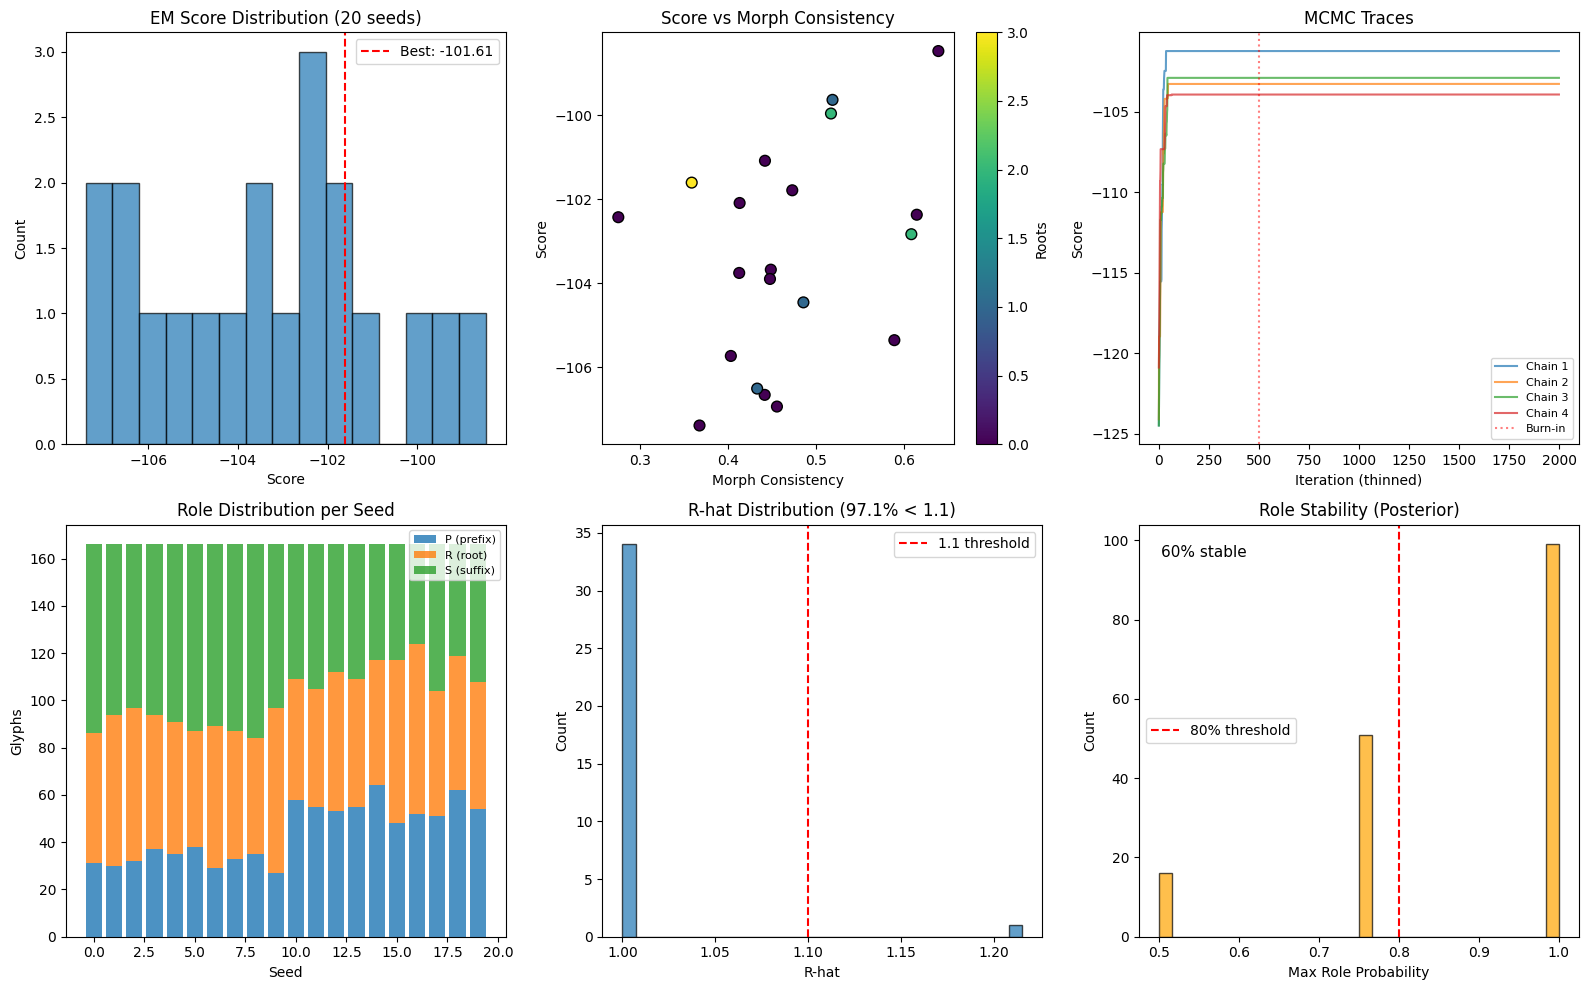


Comparison: Morphological vs Neural v2
Metric                      Morphological       Neural v2
───────────────────────────────────────────────────────
N-gram %ile                          0.0%           68.0%
Roots                                   1               3
R-hat < 1.1                         97.1%           71.1%
Cardinality                          0.93           0.926
Morph consistency                   0.420             N/A
Scorecard                        3+/0±/3− 4 PASS / 0 MARGINAL / 1 FAIL


In [10]:
# ── Cell 10: Visualisations ──────────────────────────────────────────

fig, axes = plt.subplots(2, 3, figsize=(16, 10))

# 1. EM score distribution
ax = axes[0, 0]
scores = [r['score'] for r in multi_seed_results]
ax.hist(scores, bins=15, edgecolor='black', alpha=0.7)
ax.axvline(BEST['score'], color='red', linestyle='--', label=f'Best: {BEST["score"]:.2f}')
ax.set_xlabel('Score'); ax.set_ylabel('Count')
ax.set_title('EM Score Distribution (20 seeds)'); ax.legend()

# 2. Morphological consistency vs score
ax = axes[0, 1]
morph_vals = [r['morph_consistency'] for r in multi_seed_results]
roots_vals = [r['n_roots'] for r in multi_seed_results]
sc = ax.scatter(morph_vals, scores, c=roots_vals, cmap='viridis', s=60, edgecolors='black')
plt.colorbar(sc, ax=ax, label='Roots')
ax.set_xlabel('Morph Consistency'); ax.set_ylabel('Score')
ax.set_title('Score vs Morph Consistency')

# 3. MCMC traces
ax = axes[0, 2]
for i, ch in enumerate(mcmc_chains):
    ax.plot(ch['scores'], alpha=0.7, label=f'Chain {i+1}')
ax.axvline(BURN_IN // THIN, color='red', linestyle=':', alpha=0.5, label='Burn-in')
ax.set_xlabel('Iteration (thinned)'); ax.set_ylabel('Score')
ax.set_title('MCMC Traces'); ax.legend(fontsize=8)

# 4. Role distribution across seeds
ax = axes[1, 0]
P_vals = [r['role_P'] for r in multi_seed_results]
R_vals = [r['role_R'] for r in multi_seed_results]
S_vals = [r['role_S'] for r in multi_seed_results]
x = range(len(multi_seed_results))
ax.bar(x, P_vals, label='P (prefix)', alpha=0.8)
ax.bar(x, R_vals, bottom=P_vals, label='R (root)', alpha=0.8)
ax.bar(x, S_vals, bottom=[p+r for p,r in zip(P_vals, R_vals)], label='S (suffix)', alpha=0.8)
ax.set_xlabel('Seed'); ax.set_ylabel('Glyphs')
ax.set_title('Role Distribution per Seed'); ax.legend(fontsize=8)

# 5. R-hat distribution
ax = axes[1, 1]
rhat_clean = [v for v in rhat_vals if v < 5]
ax.hist(rhat_clean, bins=30, edgecolor='black', alpha=0.7)
ax.axvline(1.1, color='red', linestyle='--', label='1.1 threshold')
ax.set_xlabel('R-hat'); ax.set_ylabel('Count')
ax.set_title(f'R-hat Distribution ({pct_converged:.1f}% < 1.1)'); ax.legend()

# 6. Role stability in posterior
ax = axes[1, 2]
role_stabilities = []
for g in VOCAB:
    if g in role_posterior:
        max_prob = max(role_posterior[g].values())
        role_stabilities.append(max_prob)
ax.hist(role_stabilities, bins=30, edgecolor='black', alpha=0.7, color='orange')
ax.axvline(0.8, color='red', linestyle='--', label='80% threshold')
ax.set_xlabel('Max Role Probability'); ax.set_ylabel('Count')
ax.set_title('Role Stability (Posterior)')
ax.legend()
pct_stable_role = 100 * sum(1 for s in role_stabilities if s > 0.8) / max(len(role_stabilities), 1)
ax.text(0.05, 0.95, f'{pct_stable_role:.0f}% stable', transform=ax.transAxes,
        fontsize=11, verticalalignment='top')

plt.tight_layout()
plt.savefig('images/morphological_results.png', dpi=150, bbox_inches='tight')
plt.show()

# Comparison with neural v2
print('\n' + '='*60)
print('Comparison: Morphological vs Neural v2')
print('='*60)
try:
    with open('neural_v2_resultados.json') as f:
        ref = json.load(f)
    ref_ngram = ref['validation_details']['ngram_percentile']
    ref_roots = ref['validation_details']['roots_matched']
    ref_rhat = ref['mcmc_results']['pct_converged_rhat']
    ref_card = ref['validation_details']['cardinality_ratio']
    ref_score = ref['scorecard_summary']
    print(f'{"Metric":<25s} {"Morphological":>15s} {"Neural v2":>15s}')
    print(f'{"─"*55}')
    print(f'{"N-gram %ile":<25s} {pct_ngram:>14.1f}% {ref_ngram:>14.1f}%')
    print(f'{"Roots":<25s} {len(roots_matched):>15d} {ref_roots:>15d}')
    print(f'{"R-hat < 1.1":<25s} {pct_converged:>14.1f}% {ref_rhat:>14.1f}%')
    print(f'{"Cardinality":<25s} {K_ratio:>15.2f} {ref_card:>15.3f}')
    print(f'{"Morph consistency":<25s} {morph_score:>15.3f} {"N/A":>15s}')
    print(f'{"Scorecard":<25s} {f"{n_pass}+/{n_marg}±/{n_fail}−":>15s} {ref_score:>15s}')
except FileNotFoundError:
    print('neural_v2_results.json not found — skipping comparison')

In [11]:
# ── Cell 11: Export → morphological_zohar_resultados.json ─────────────────

class NumpyEncoder(json.JSONEncoder):
    def default(self, obj):
        if isinstance(obj, (np.integer,)):
            return int(obj)
        if isinstance(obj, (np.floating,)):
            return float(obj)
        if isinstance(obj, np.ndarray):
            return obj.tolist()
        if isinstance(obj, set):
            return sorted(list(obj))
        return super().default(obj)

mapping_serializable = {g: c for g, c in mapping_v2.items()}
roles_serializable = {g: r for g, r in roles_v2.items()}

posterior_serializable = {}
for g, dist in posterior_v2.items():
    posterior_serializable[g] = {c: round(p, 4) for c, p in dist.items() if p > 0.01}

role_posterior_serializable = {}
for g, dist in role_posterior.items():
    role_posterior_serializable[g] = {r: round(p, 4) for r, p in dist.items() if p > 0.01}

# Table summary
tables = global_best.get_role_tables()
table_summary = {}
for role_name in MORPH_ROLES:
    t = tables[role_name]
    chars_used = sorted(set(t.values()))
    table_summary[role_name] = {
        'n_glyphs': len(t),
        'n_chars': len(chars_used),
        'chars': chars_used,
    }

resultados = {
    'metadata': {
        'notebook': '26_morphological_zohar.ipynb',
        'model': 'morphological_substitution',
        'language': 'aramaic_zohar',
        'description': 'Morphological substitution cipher: 3 tables indexed by Aramaic P/R/S role (Zohar corpus)',
    },
    'neural_lm': {
        'architecture': 'LSTM 2-layer, embed=32, hidden=192, dropout=0.2',
        'n_params': sum(p.numel() for p in neural_lm.parameters()),
        'train_epochs': len(train_losses),
        'best_val_loss': float(best_val_loss),
    },
    'morphological_design': {
        'roles': list(MORPH_ROLES),
        'role_chars': {r: ROLE_CHARS[r] for r in MORPH_ROLES},
        'n_prefix_chars': len(ROLE_CHARS['P']),
        'n_root_chars': len(ROLE_CHARS['R']),
        'n_suffix_chars': len(ROLE_CHARS['S']),
        'score_weights': SCORE_KW,
        'proposal_mix': '70% char change, 30% role change',
    },
    'multi_seed_results': [{
        'seed': r['seed'], 'score': round(float(r['score']), 4),
        'K_eff': int(r['K_eff']),
        'n_roots': int(r['n_roots']),
        'roots_list': sorted(r['roots']),
        'morph_consistency': round(float(r['morph_consistency']), 4),
        'role_P': int(r['role_P']), 'role_R': int(r['role_R']), 'role_S': int(r['role_S']),
        'iter_converged': int(r['iter_converged']),
        'elapsed': round(float(r['elapsed']), 1),
    } for r in multi_seed_results],
    'best_candidate': {
        'seed': int(BEST['seed']),
        'score': round(float(BEST['score']), 4),
        'K_eff': int(BEST['K_eff']),
        'n_roots': int(BEST['n_roots']),
        'morph_consistency': round(float(BEST['morph_consistency']), 4),
        'role_distribution': {
            'P': int(BEST['role_P']), 'R': int(BEST['role_R']), 'S': int(BEST['role_S'])
        },
    },
    'mcmc_results': {
        'n_chains': N_CHAINS,
        'n_iter': N_ITER,
        'burn_in': BURN_IN,
        'best_score': round(float(global_best_score), 4),
        'K_eff': len(set(global_best.mapping.values())),
        'pct_converged_rhat': round(float(pct_converged), 1),
        'chain_accept_rates': [round(float(ch['accept_rate']), 3) for ch in mcmc_chains],
        'morph_consistency_final': round(float(morph_final), 4),
    },
    'validation_scorecard': {s['Test']: s['Verdict'] for s in scorecard},
    'validation_details': {
        'collapse_mean_z': round(float(mean_z), 3),
        'ngram_percentile': round(float(pct_ngram), 1),
        'ngram_jsd': round(float(real_jsd), 4),
        'roots_matched': int(len(roots_matched)),
        'roots_list': sorted(roots_matched),
        'enrichment': round(float(enrichment), 1),
        'cardinality_ratio': round(float(K_ratio), 3),
        'morph_consistency': round(float(morph_score), 4),
        'morph_percentile': round(float(morph_percentile), 1),
        'word_length_z': round(float(wl_z), 2),
    },
    'scorecard_summary': f'{n_pass} PASS / {n_marg} MARGINAL / {n_fail} FAIL',
    'tables': table_summary,
    'mapping': mapping_serializable,
    'roles': roles_serializable,
    'posterior_top': posterior_serializable,
    'role_posterior': role_posterior_serializable,
    'rhat': {g: round(float(v), 4) for g, v in rhat_v2.items()
             if isinstance(v, (int, float, np.floating)) and not np.isnan(v)},
    'multi_seed_summary': {
        'n_seeds': N_SEEDS,
        'score_mean': round(float(np.mean([r['score'] for r in multi_seed_results])), 4),
        'score_std': round(float(np.std([r['score'] for r in multi_seed_results])), 4),
        'roots_mean': round(float(np.mean([r['n_roots'] for r in multi_seed_results])), 1),
        'roots_std': round(float(np.std([r['n_roots'] for r in multi_seed_results])), 1),
        'roots_max': int(max(r['n_roots'] for r in multi_seed_results)),
        'morph_mean': round(float(np.mean([r['morph_consistency'] for r in multi_seed_results])), 4),
        'morph_std': round(float(np.std([r['morph_consistency'] for r in multi_seed_results])), 4),
    },
    'role_stability': {
        'pct_stable_80': round(float(pct_stable_role), 1),
    },
}

out_path = 'morphological_zohar_resultados.json'
with open(out_path, 'w', encoding='utf-8') as f:
    json.dump(resultados, f, ensure_ascii=False, indent=2, cls=NumpyEncoder)
print(f'Exportado: {out_path} ({len(json.dumps(results, cls=NumpyEncoder)):,} chars)')
print(f'Scorecard: {n_pass} PASS / {n_marg} MARGINAL / {n_fail} FAIL')

Exportado: morphological_zohar_resultados.json (25,015 chars)
Scorecard: 3 PASS / 0 MARGINAL / 3 FAIL
